# Clusteranalyse

## Präambel

Wir laden alle Pakete und Module, die wir im Folgenden benötigen.

In [1]:
# Paket für Daten
import kagglehub

# Visualisierung und Datentransformation
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Pakete für Clusteranalyse und Feature Selection
from sklearn import preprocessing
from sklearn.cluster import DBSCAN, Birch, KMeans, SpectralClustering
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.neighbors import NearestNeighbors, kneighbors_graph

# Paket für Netzwerke
import networkx as nx

# Pakete für Landkarten
import geopandas # Achte auf die Version: https://stackoverflow.com/questions/5226311/installing-specific-package-version-with-pip
from pyproj import Transformer

## Daten

Whisky-Datensatz von https://www.kaggle.com/datasets/koki25ando/scotch-whisky-dataset

In [2]:
path = kagglehub.dataset_download("koki25ando/scotch-whisky-dataset") # Pfad zum heruntergeladenen Datensatz

# Lies die Daten ein
df = pd.read_csv(path + '/whisky.csv')

# Erster Blick auf den Datensatz
df

100%|██████████| 2.59k/2.59k [00:00<00:00, 1.43MB/s]

Extracting files...


,RowID,Distillery,Body,Sweetness,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Fruity,Floral,Postcode,Latitude,Longitude
0,1,Aberfeldy,2,2,2,0,0,2,1,2,2,2,2,2,\tPH15 2EB,286580,749680
1,2,Aberlour,3,3,1,0,0,4,3,2,2,3,3,2,\tAB38 9PJ,326340,842570
2,3,AnCnoc,1,3,2,0,0,2,0,0,2,2,3,2,\tAB5 5LI,352960,839320
3,4,Ardbeg,4,1,4,4,0,0,2,0,1,2,1,0,\tPA42 7EB,141560,646220
4,5,Ardmore,2,2,2,0,0,1,1,1,2,3,1,1,\tAB54 4NH,355350,829140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81,82,Tobermory,1,1,1,0,0,1,0,0,1,2,2,2,PA75 6NR,150450,755070
82,83,Tomatin,2,3,2,0,0,2,2,1,1,2,0,1,IV13 7YT,279120,829630
83,84,Tomintoul,0,3,1,0,0,2,2,1,1,2,1,2,AB37 9AQ,315100,825560
84,85,Tormore,2,2,1,0,0,1,0,1,2,1,0,0,PH26 3LR,315180,834960


Jede Zeile ist eine von 86 schottischen Destillerien. Für jede Destillerie gibt es zwölf Geschmacksmerkmale (`Body` bis `Floral`), die auf einer Skala von 0 (nicht vorhanden) bis 4 (sehr ausgeprägt) bewertet wurden. Dazu kommen die Postleitzahl (`Postcode`) und die Koordinaten der Destillerie (`Latitude`, `Longitude`).

Die Ausgaben oberhalb der Tabelle stammen von `kagglehub` und zeigen nur, dass der Datensatz heruntergeladen und entpackt wurde.

Der Datensatz enthält die Koordinaten der einzelnen Destillerien. Das könnte man sich auf einer Karte ansehen...

## Exkurs A: Landkarten in Python

Das Paket `geopandas` bietet einen Rahmen für die Arbeit mit Geodaten. Das Modul `Transformer` aus dem Paket `pyproj` wird verwendet, um Koordinatensysteme von einem Standard in einen anderen zu konvertieren.

Zunächst laden wir eine Karte von UK.

In [3]:
# https://simplemaps.com/gis/country/gb
file = open("gb.json") # 4326-projection
ctry = geopandas.read_file(file)
ctry

,source,id,name,geometry
0,https://simplemaps.com,GBDRY,Derry,"POLYGON ((-7.41576 54.94437, -7.40866 54.95112..."
1,https://simplemaps.com,GBSTB,Strabane,"POLYGON ((-7.41576 54.94437, -7.41474 54.94373..."
2,https://simplemaps.com,GBFER,Fermanagh,"POLYGON ((-7.70795 54.60476, -7.69338 54.60075..."
3,https://simplemaps.com,GBDGN,Dungannon,"POLYGON ((-7.18947 54.33569, -7.18971 54.33604..."
4,https://simplemaps.com,GBARM,Armagh,"POLYGON ((-6.87001 54.326, -6.86743 54.3279, -..."
...,...,...,...,...
227,https://simplemaps.com,GBBIR,Birmingham,"POLYGON ((-1.85559 52.5755, -1.83169 52.58775,..."
228,https://simplemaps.com,GBSAW,Sandwell,"POLYGON ((-1.90281 52.54676, -1.91466 52.5278,..."
229,https://simplemaps.com,GBDUD,Dudley,"POLYGON ((-2.15387 52.42295, -2.15893 52.47742..."
230,https://simplemaps.com,GBWLL,Walsall,"POLYGON ((-2.05088 52.61743, -2.02589 52.61607..."


`ctry` ist ein `GeoDataFrame`: eine Tabelle wie in `pandas`, in der jede Zeile eine Region des Vereinigten Königreichs ist (insgesamt 232). Die Spalte `geometry` enthält die Umrisse der Regionen als Polygone in Längen- und Breitengraden.

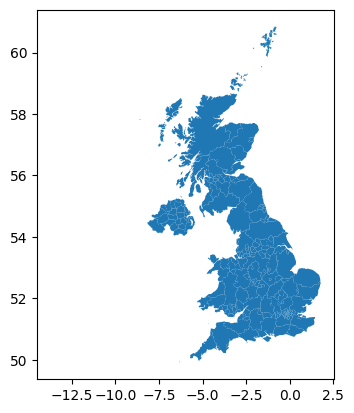

In [4]:
# Zeichne die Karte (alle Regionen des Vereinigten Königreichs)
ctry.plot()
plt.show()

Die Karte zeigt das gesamte Vereinigte Königreich inklusive Nordirland. Die Achsen sind in Grad angegeben: Längengrade auf der x-Achse, Breitengrade auf der y-Achse.

Dann legen wir unsere Daten über die Karte...

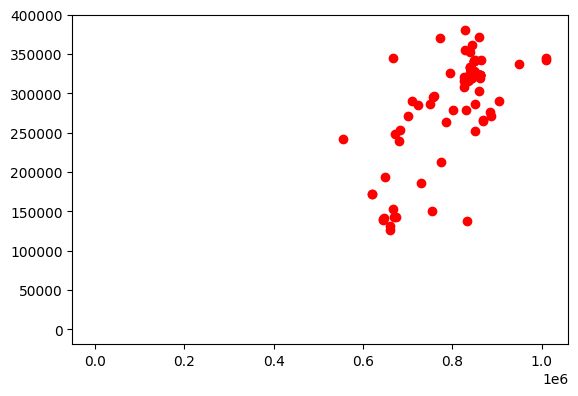

In [5]:
# Zeichne die Karte und lege die Destillerien als rote Punkte darüber
ctry.plot()
plt.scatter(x = df[['Longitude']], y = df[['Latitude']], marker='o', c = "red")
plt.show()

Die Punkte landen nicht auf der Karte: Die Achsen reichen jetzt bis 1.000.000 bzw. 400.000, und die Karte ist im Ursprung links unten nicht mehr zu erkennen. Der Grund ist, dass die Koordinaten im Whisky-Datensatz nicht in Grad, sondern im britischen Koordinatensystem *British National Grid* (EPSG:27700) in Metern angegeben sind. Außerdem sind die Spaltennamen irreführend: `Latitude` enthält den Ost-Wert (x) und `Longitude` den Nord-Wert (y). Deshalb übergeben wir im nächsten Schritt `Latitude` als erste Koordinate an den Transformer.

Wir müssen die Koordinatensysteme in ein einheitliches Format bringen. Dazu werden die Daten im Whisky-Datensatz transformiert:

In [6]:
coords = df[['Latitude', 'Longitude']]
coords_new = []

# Stelle den Transformer ein
transformer = Transformer.from_crs("EPSG:27700", "EPSG:4326", always_xy=True) # always_xy behält unabhängig vom Koordinatensystem die Reihenfolge Längengrad, Breitengrad (x, y) bei

# Führe die Transformation für jede Zeile aus
for i in range(len(coords)):
    coord_i = transformer.transform(coords.iloc[i, 0], coords.iloc[i, 1])
    coord_i = pd.DataFrame({'Longitude': [coord_i[0]], 'Latitude': [coord_i[1]]})
    coords_new.append(coord_i)

# Wandle die Liste in einen einzigen Data Frame um
coords_new = pd.concat(coords_new)

# Setze den Index neu
coords_new = coords_new.reset_index()

# Zeige Ergebnis an
coords_new

,index,Longitude,Latitude
0,0,-3.850199,56.625191
1,0,-3.229644,57.467395
2,0,-2.785295,57.441751
3,0,-6.108503,55.640607
4,0,-2.743628,57.350557
...,...,...,...
81,0,-6.069530,56.620806
82,0,-4.010031,57.341101
83,0,-3.411083,57.312680
84,0,-3.412996,57.397107


Jetzt liegen die Koordinaten in Längen- und Breitengraden vor (EPSG:4326, dasselbe System wie die Karte). Die Spalte `index` enthält überall 0, weil jeder Teil-Data-Frame in der Schleife nur eine Zeile hatte; sie wird nicht weiter verwendet.

`coords.iloc[i, 0]` greift auf Zeile `i` und Spalte 0 zu, also auf den Ost-Wert der Destillerie, `coords.iloc[i, 1]` auf den Nord-Wert.

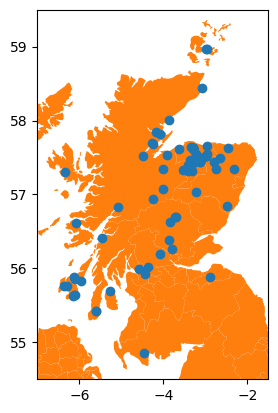

In [7]:
# Plotte Landkarte von UK
ctry.plot(color = "tab:orange")

# Füge Punkte hinzu
plt.scatter(x = coords_new[['Longitude']], y = coords_new[['Latitude']], marker='o', c = "tab:blue")

# Trimme die Grafik
plt.axis([-7, -1.5, 54.5, 59.5])

plt.show()

Nun passen Karte und Daten zusammen. Man erkennt bereits Regionen mit vielen Destillerien: eine starke Konzentration im Nordosten (Speyside), eine Gruppe auf der Insel Islay im Südwesten und einzelne Destillerien auf den Inseln und an der Küste.

## Datenaufbereitung für die Clusteranalyse

Für die Analyse bereiten wir den Datensatz ein letztes Mal auf.

In [8]:
# Lösche Spalten, die nicht benötigt werden
#x = df.drop(columns = ['RowID', 'Distillery', 'Postcode', 'Latitude', 'Longitude'])
x = df.drop(columns = ['RowID', 'Distillery', 'Postcode', 'Longitude', 'Latitude', 'Fruity', 'Sweetness'])

# Zeige Ergebnis
x

,Body,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral
0,2,2,0,0,2,1,2,2,2,2
1,3,1,0,0,4,3,2,2,3,2
2,1,2,0,0,2,0,0,2,2,2
3,4,4,4,0,0,2,0,1,2,0
4,2,2,0,0,1,1,1,2,3,1
...,...,...,...,...,...,...,...,...,...,...
81,1,1,0,0,1,0,0,1,2,2
82,2,2,0,0,2,2,1,1,2,1
83,0,1,0,0,2,2,1,1,2,2
84,2,1,0,0,1,0,1,2,1,0


Für die Clusteranalyse nach Geschmack behalten wir nur die Geschmacksmerkmale. ID, Name, Postleitzahl und Koordinaten werden entfernt, ebenso die Merkmale `Fruity` und `Sweetness`. Es bleiben 86 Destillerien mit 10 Merkmalen.

### Normalisiere die Daten

In [9]:
# Skaliere jedes Merkmal auf den Bereich [0, 1]: (x - min) / (max - min)
min_max_scaler = preprocessing.MinMaxScaler()
x_scaled = min_max_scaler.fit_transform(x)

# fit_transform liefert ein NumPy-Array, daher wandeln wir es wieder in einen Data Frame um
x_scaled = pd.DataFrame(x_scaled)
x_scaled.columns = x.columns

x_scaled

,Body,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral
0,0.50,0.50,0.0,0.0,0.50,0.333333,0.50,0.50,0.666667,0.50
1,0.75,0.25,0.0,0.0,1.00,1.000000,0.50,0.50,1.000000,0.50
2,0.25,0.50,0.0,0.0,0.50,0.000000,0.00,0.50,0.666667,0.50
3,1.00,1.00,1.0,0.0,0.00,0.666667,0.00,0.25,0.666667,0.00
4,0.50,0.50,0.0,0.0,0.25,0.333333,0.25,0.50,1.000000,0.25
...,...,...,...,...,...,...,...,...,...,...
81,0.25,0.25,0.0,0.0,0.25,0.000000,0.00,0.25,0.666667,0.50
82,0.50,0.50,0.0,0.0,0.50,0.666667,0.25,0.25,0.666667,0.25
83,0.00,0.25,0.0,0.0,0.50,0.666667,0.25,0.25,0.666667,0.50
84,0.50,0.25,0.0,0.0,0.25,0.000000,0.25,0.50,0.333333,0.00


Nach der Min-Max-Normalisierung liegen alle Merkmale zwischen 0 und 1. Das ist wichtig, weil k-means mit Distanzen arbeitet: Ohne Normalisierung hätten Merkmale mit größerer Spannweite automatisch mehr Gewicht. Ein Wert von 0,5 bei `Body` bedeutet hier, dass die Destillerie genau in der Mitte zwischen dem kleinsten und dem größten beobachteten Wert liegt.

In [10]:
# Korrelationsmatrix der (skalierten) Geschmacksmerkmale
x_scaled.corr()

,Body,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral
Body,1.000000,0.524032,0.354050,0.168718,0.082031,0.188500,0.408576,0.126323,-0.116859,-0.461203
Smoky,0.524032,1.000000,0.686071,0.365501,-0.195318,0.231745,-0.028190,-0.023132,-0.192875,-0.431663
Medicinal,0.354050,0.686071,1.000000,0.425106,-0.396629,0.044903,-0.202651,-0.113671,-0.258959,-0.511323
Tobacco,0.168718,0.365501,0.425106,1.000000,-0.275490,0.054068,0.009097,-0.117717,-0.059347,-0.212375
Honey,0.082031,-0.195318,-0.396629,-0.275490,1.000000,0.139563,0.362021,0.188492,0.310184,0.183029
Spicy,0.188500,0.231745,0.044903,0.054068,0.139563,1.000000,0.092704,-0.042856,0.036303,0.034663
Winey,0.408576,-0.028190,-0.202651,0.009097,0.362021,0.092704,1.000000,0.198467,0.112368,-0.126932
Nutty,0.126323,-0.023132,-0.113671,-0.117717,0.188492,-0.042856,0.198467,1.000000,0.066157,0.018302
Malty,-0.116859,-0.192875,-0.258959,-0.059347,0.310184,0.036303,0.112368,0.066157,1.000000,0.106309
Floral,-0.461203,-0.431663,-0.511323,-0.212375,0.183029,0.034663,-0.126932,0.018302,0.106309,1.000000


Die Korrelationsmatrix zeigt, welche Geschmacksmerkmale gemeinsam auftreten:

* `Smoky` und `Medicinal` hängen stark positiv zusammen (0,69), ebenso `Body` und `Smoky` (0,52). Rauchige Whiskys sind also oft auch medizinisch und vollmundig.
* `Floral` hängt negativ mit `Medicinal` (−0,51), `Body` (−0,46) und `Smoky` (−0,43) zusammen. Blumige Whiskys sind eher leicht und nicht rauchig.

Diese Zusammenhänge deuten darauf hin, dass es unterschiedliche Geschmacksprofile gibt, die eine Clusteranalyse finden könnte.

## k-means Clustering

### Training

Wir verwenden Funktionen des `scikit-learn` Pakets. Daher ist der Workflow ähnlich wie im Kapitel zu "Classification".

In [11]:
# Erstelle ein 'leeres' Modell
# mit der Annahme, dass 3 Cluster in den Daten zu finden sind.
kmeans = KMeans(n_clusters = 3, n_init = 'auto')

# Trainiere das Modell
kmeans.fit(x_scaled)

KMeans(n_clusters=3)

Die Ausgabe zeigt nur das trainierte Modell mit seinen Parametern. Die eigentlichen Ergebnisse fragen wir in den nächsten Zellen ab.

In [12]:
# Zeige die 'Koordinaten' der repräsentativen Punkte an
kmeans.cluster_centers_

array([[ 6.32352941e-01,  4.04411765e-01,  5.14705882e-02,
        -9.71445147e-17,  4.48529412e-01,  5.68627451e-01,
         4.19117647e-01,  4.41176471e-01,  6.66666667e-01,
         4.04411765e-01],
       [ 6.87500000e-01,  6.45833333e-01,  5.00000000e-01,
         8.33333333e-01,  1.45833333e-01,  5.55555556e-01,
         2.08333333e-01,  2.91666667e-01,  5.83333333e-01,
         2.50000000e-01],
       [ 3.68750000e-01,  2.87500000e-01,  1.00000000e-01,
        -1.24900090e-16,  2.43750000e-01,  3.41666667e-01,
         1.06250000e-01,  3.25000000e-01,  5.50000000e-01,
         4.93750000e-01]])

Jede Zeile ist das Zentrum eines Clusters, jede Spalte ein Merkmal in der Reihenfolge von `x_scaled` (`Body`, `Smoky`, `Medicinal`, `Tobacco`, `Honey`, `Spicy`, `Winey`, `Nutty`, `Malty`, `Floral`). Werte wie `-9.7e-17` sind Rundungsfehler und bedeuten 0.

In diesem Durchlauf lassen sich die Zentren so lesen:

* **Cluster 0**: vollmundig (`Body` 0,63), würzig (`Spicy` 0,57), malzig (`Malty` 0,67) mit etwas Honig, also eher kräftige, runde Whiskys.
* **Cluster 1**: rauchig (`Smoky` 0,65), medizinisch (`Medicinal` 0,50) und mit Tabaknote (`Tobacco` 0,83), also die typischen torfigen Whiskys.
* **Cluster 2**: insgesamt niedrige Werte, aber eher blumig (`Floral` 0,49), also leichte, milde Whiskys.

Achtung: k-means startet mit zufälligen Zentren. Bei einem neuen Durchlauf können die Nummern der Cluster vertauscht sein.

In [13]:
# Weise jede Destillerie dem nächstgelegenen Clusterzentrum zu
kmeans.predict(x_scaled)

array([0, 0, 2, 1, 0, 2, 2, 0, 2, 2, 0, 0, 0, 2, 0, 0, 2, 0, 0, 0, 2, 1,
       2, 1, 1, 2, 0, 0, 2, 0, 2, 0, 1, 2, 0, 2, 0, 2, 0, 2, 2, 2, 0, 0,
       0, 2, 2, 2, 0, 2, 2, 0, 0, 0, 2, 2, 0, 1, 1, 2, 2, 0, 0, 2, 2, 0,
       2, 1, 1, 1, 0, 2, 2, 2, 0, 0, 2, 1, 2, 2, 2, 2, 0, 2, 2, 1],
      dtype=int32)

Für jede der 86 Destillerien (in der Reihenfolge des Datensatzes) gibt die Ausgabe die Nummer des Clusters an. In diesem Durchlauf sind 34 Destillerien in Cluster 0, 12 in Cluster 1 und 40 in Cluster 2. Im rauchigen Cluster 1 finden sich unter anderem Ardbeg, Lagavulin, Laphroaig und Caol Ila von der Insel Islay sowie Talisker von der Isle of Skye.

### Wähle die Anzahl der Cluster

Eine beliebte Methode für die Auswahl der Anzahl der Cluster ist die 'Elbow'-Methode. Dafür wird der K-Means-Algorithmus für eine Reihe von Kandidaten ausgeführt.

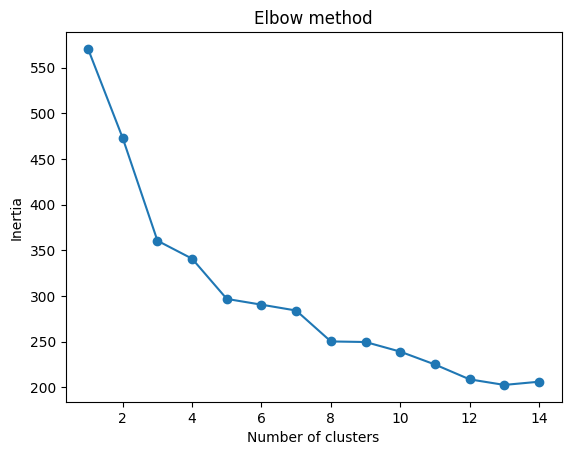

In [14]:
# Anzahl der Cluster, für die der Algorithmus ausgeführt werden soll
max_clusters = 15

# Leerer Datensatz, der die finalen Resultate enthalten wird
inertias = []

# Schleife: Für jeden Cluster-Wert i...
for i in range(1,max_clusters):
    # ...generiere ein leeres Modell unter der Annahme, dass es i Cluster enthält
    kmeans = KMeans(n_clusters = i, n_init = 'auto')
    # ...trainiere das Modell mit den Daten
    kmeans.fit(x)
    # ...füge die Kennzahl 'Inertia' in den finalen Datensatz ein
    inertias.append(kmeans.inertia_)

# Stelle das Resultat grafisch dar
plt.plot(range(1,max_clusters), inertias, marker='o')
plt.title('Elbow method')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()

Nachdem die Kurve ab dem 3. Punkt nicht mehr so schnell fällt wie zuvor, könnte man darauf schließen, dass der Datensatz drei wesentliche Cluster enthält. Die Kurve hat allerdings keinen ganz eindeutigen Knick: Auch bei 5 Clustern flacht sie noch einmal ab. Die Elbow-Methode ist daher eher eine Orientierungshilfe als eine exakte Regel.

## Hierarchical clustering

Birch (*Balanced Iterative Reducing and Clustering using Hierarchies*) ist ein hierarchisches Verfahren. Auch hier geben wir die gewünschte Anzahl an Clustern vor.

In [15]:
# Erstelle ein 'leeres' Modell
birch = Birch(n_clusters = 3)

# Trainiere das Modell
birch.fit(x_scaled)

Birch()

Die Ausgabe zeigt wieder nur das Modell. Birch baut zuerst einen Baum aus kleinen Teil-Clustern auf und fasst diese dann hierarchisch zu den gewünschten 3 Clustern zusammen. Anders als k-means verwendet Birch keine zufälligen Startwerte, das Ergebnis ist also bei jedem Durchlauf gleich.

In [16]:
# Clusterzuordnung jeder Destillerie
birch.predict(x_scaled)

array([0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 2, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 2])

Wie bei k-means erhalten wir für jede Destillerie die Nummer ihres Clusters. Die Cluster sind hier sehr ungleich groß: 74 Destillerien in Cluster 0 und je 6 in den Clustern 1 und 2.

* **Cluster 1** enthält die stark rauchigen, medizinischen Whiskys: Ardbeg, Caol Ila, Lagavulin, Laphroaig, Talisker und Clynelish.
* **Cluster 2** enthält die Whiskys mit Tabaknote: Craigellachie, Glen Deveron, Old Fettercairn, Old Pulteney, Royal Brackla und Tullibardine.
* **Cluster 0** fasst alle übrigen Destillerien zusammen.

Im Vergleich zu k-means teilt Birch also das rauchige Cluster von k-means in zwei Gruppen (torfig vs. Tabak) und legt dafür die beiden anderen k-means-Cluster zu einem großen Cluster zusammen. Die Nummern von Birch und k-means sind unabhängig voneinander, Cluster 0 bei Birch entspricht also nicht automatisch Cluster 0 bei k-means.

Wichtig: Für `predict` verwenden wir dieselben skalierten Daten `x_scaled`, mit denen das Modell trainiert wurde.

## Exkurs B: Lassen sich regionale Cluster erkennen?

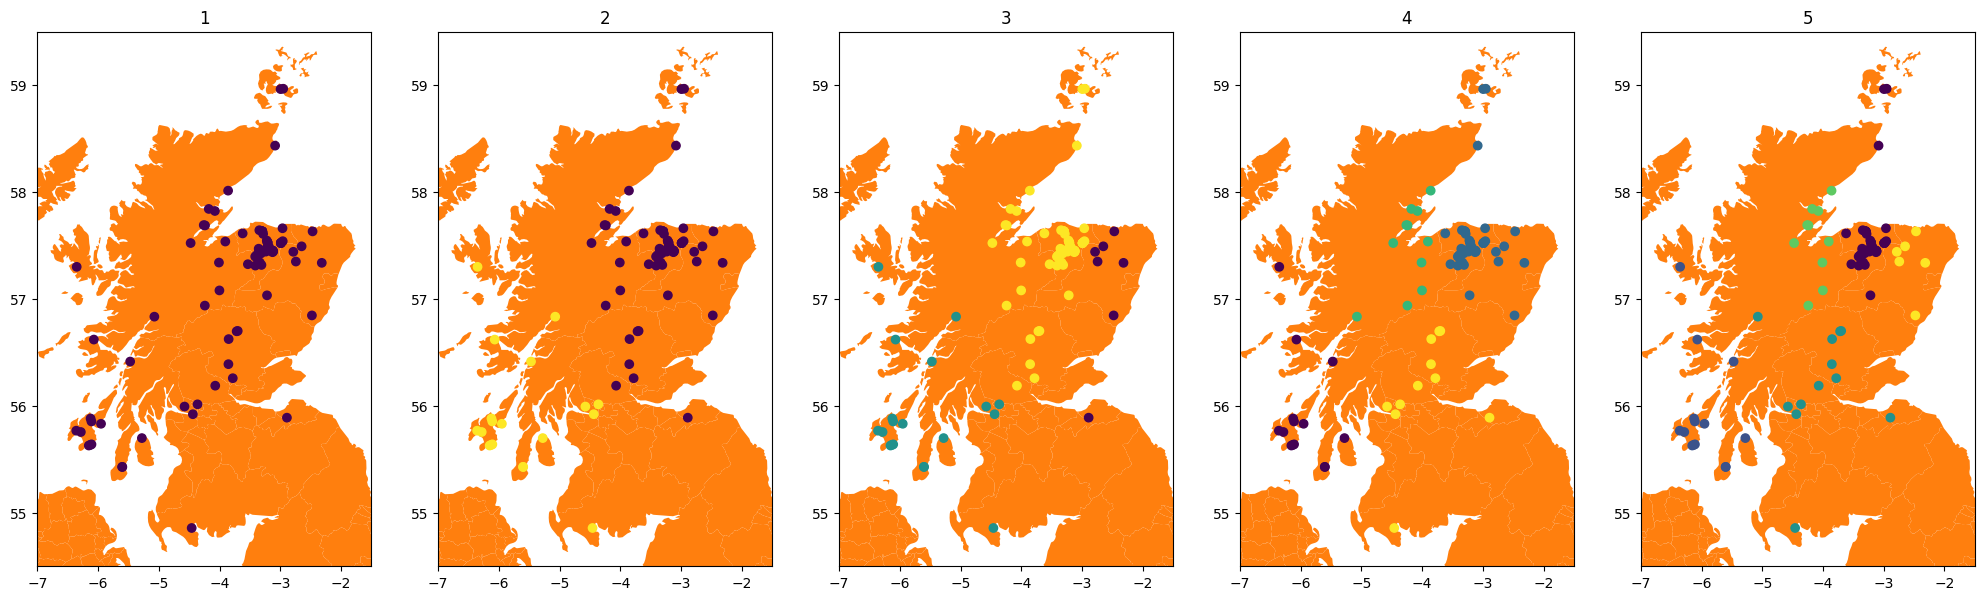

In [17]:
# Lösche Spalten, die nicht benötigt werden
#x = df.drop(columns = ['RowID', 'Distillery', 'Postcode', 'Latitude', 'Longitude'])
x = df.drop(columns = ['RowID', 'Distillery', 'Postcode', 'Fruity', 'Sweetness'])
x = x[["Longitude", "Latitude"]]

min_max_scaler = preprocessing.MinMaxScaler()
x_scaled = min_max_scaler.fit_transform(x)
x_scaled = pd.DataFrame(x_scaled)
x_scaled.columns = x.columns


max_k = 5

fig, axes = plt.subplots(1, max_k, figsize = (25, 25))
axes = axes.flatten()

for i in range(1, max_k + 1):
    kmeans = KMeans(n_clusters = i, n_init = 'auto')
    kmeans.fit(x_scaled)
    pred = kmeans.predict(x_scaled)
    ctry.plot(ax = axes[i - 1], color = "tab:orange")
    axes[i - 1].axis([-7, -1.5, 54.5, 59.5]) # Durch Ausprobieren ermittelt
    axes[i - 1].scatter(x = coords_new[['Longitude']], y = coords_new[['Latitude']], marker='o', c = pred)
    axes[i - 1].set_title(i)

plt.show()

In diesem Exkurs clustern wir die Destillerien nicht nach Geschmack, sondern nur nach ihrem Standort. Jede Teilgrafik zeigt das Ergebnis von k-means für 1 bis 5 Cluster, die Farbe gibt das Cluster an (die Farben sind in jeder Teilgrafik neu vergeben).

Bei 2 Clustern trennt der Algorithmus die Destillerien im Südwesten (Islay, Campbeltown) vom Rest. Mit jedem weiteren Cluster werden der Norden und der Nordosten weiter aufgeteilt, wobei die dichte Gruppe in der Speyside meist zusammen bleibt. Da k-means immer runde Cluster um ein Zentrum bildet, werden einzelne abgelegene Destillerien dabei immer irgendeinem Cluster zugeschlagen.

### Silhouette-Analyse

Die Silhouette-Analyse zeigt, wie gut jede Beobachtung zu ihrem Cluster passt. Der Code folgt einem Beispiel aus der Dokumentation von `scikit-learn` (siehe Quellen).

For n_clusters = 2 The average silhouette_score is : 0.6877368527491624
For n_clusters = 3 The average silhouette_score is : 0.5866407167419374
For n_clusters = 4 The average silhouette_score is : 0.5571456972448381
For n_clusters = 5 The average silhouette_score is : 0.5336587725126227
For n_clusters = 6 The average silhouette_score is : 0.5808401752655633


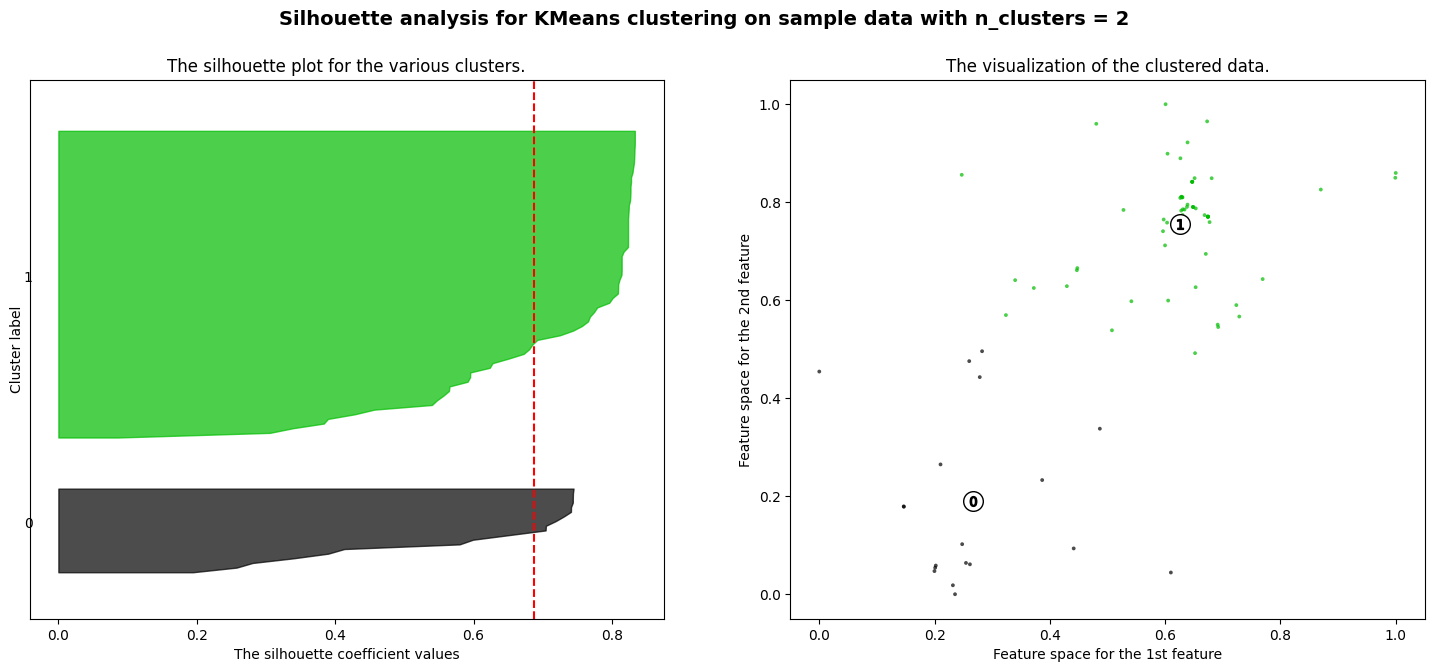

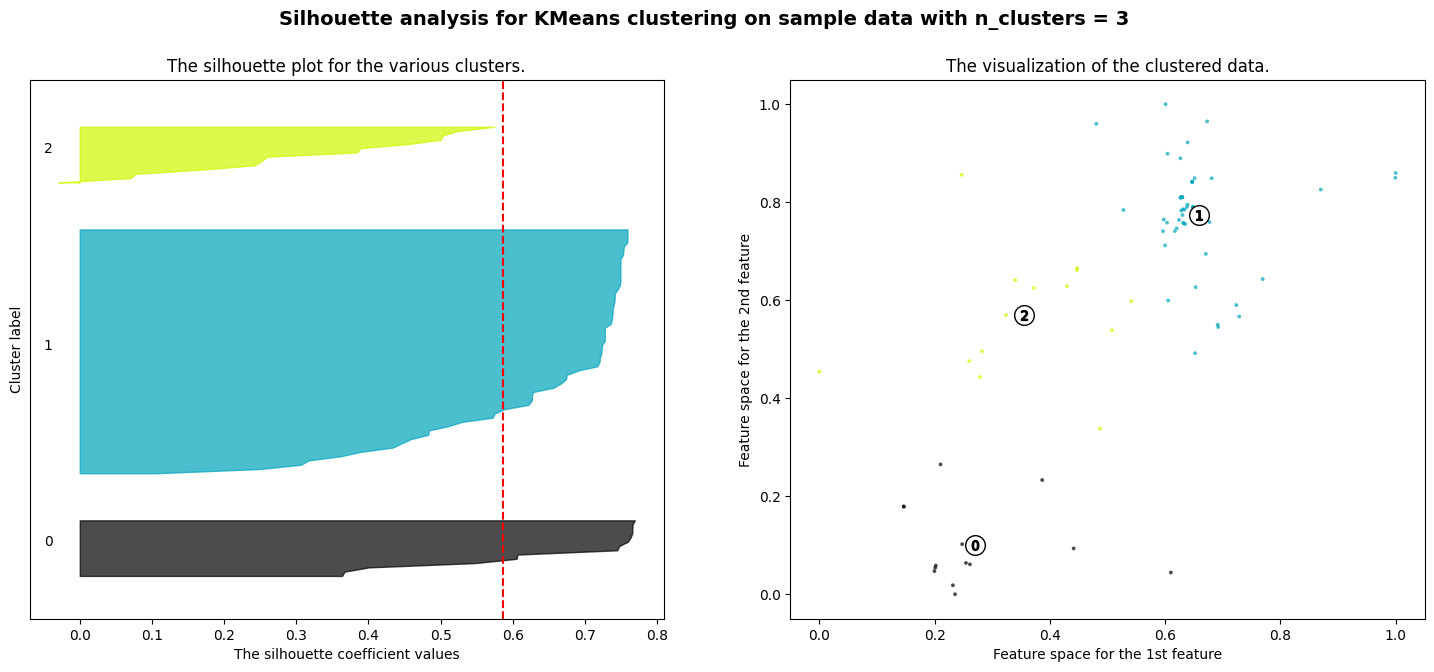

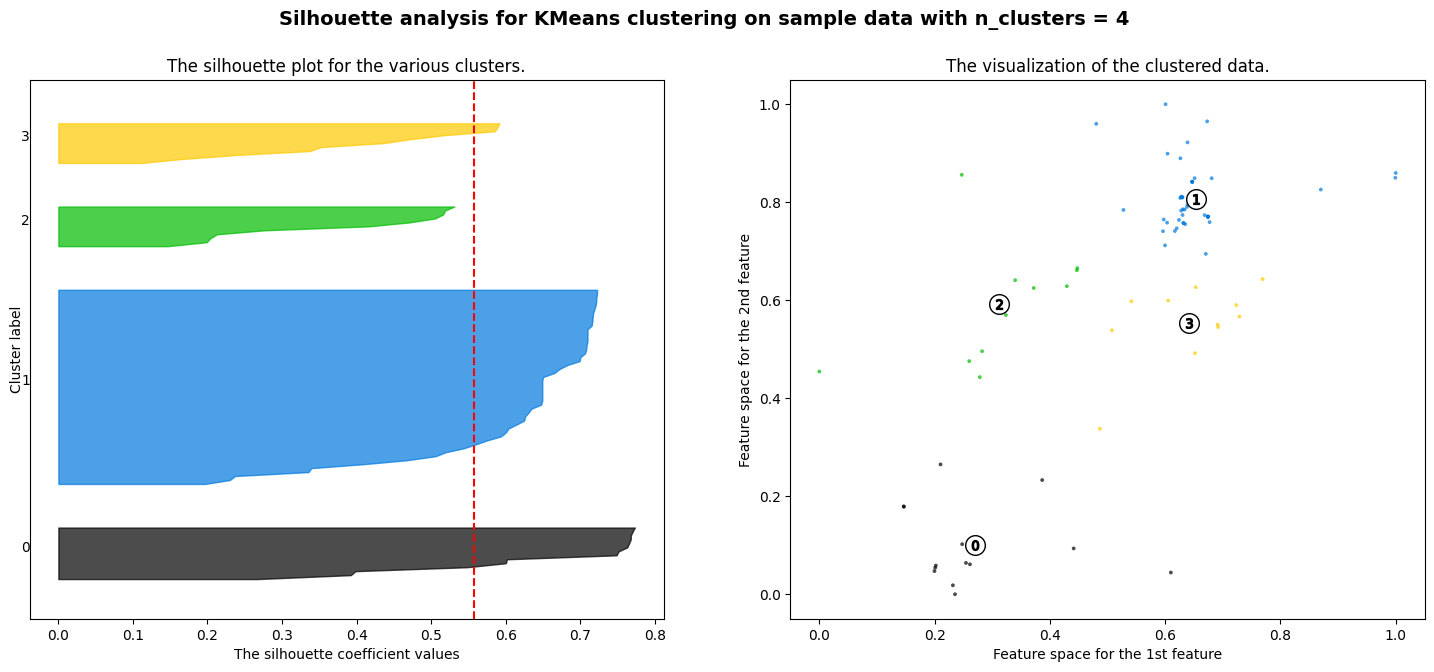

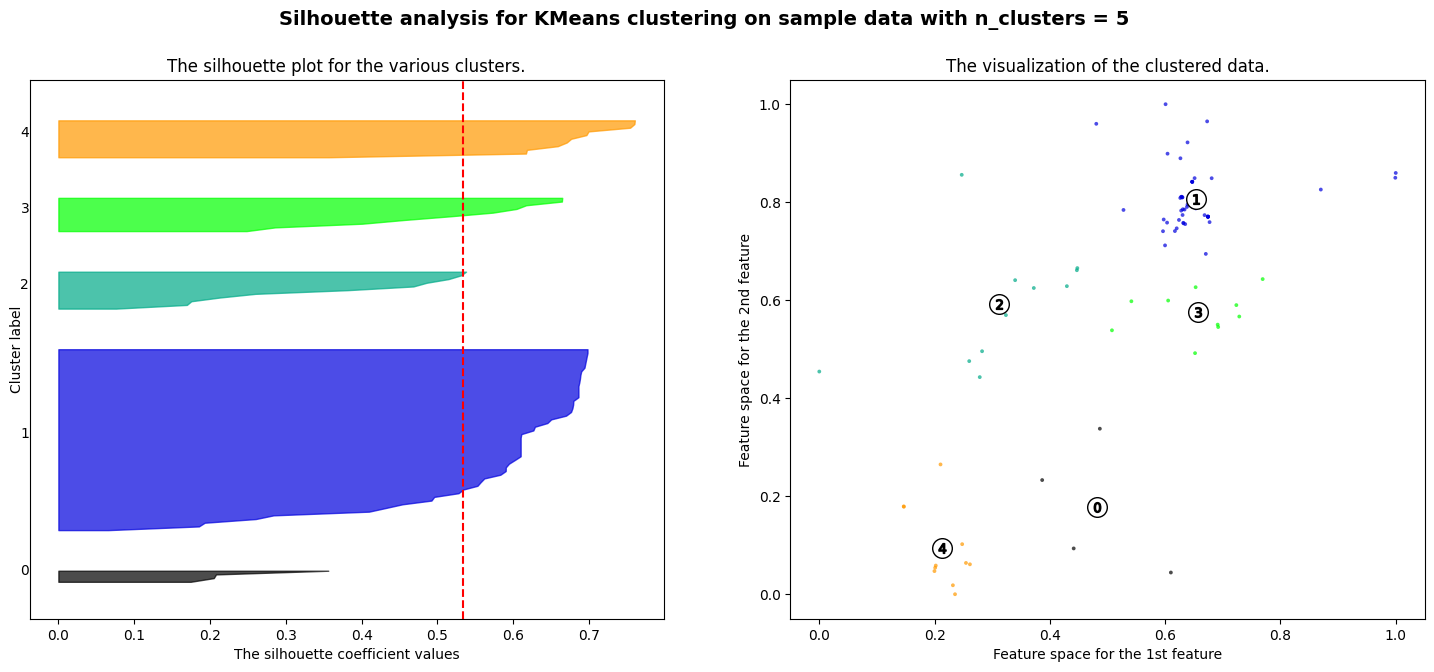

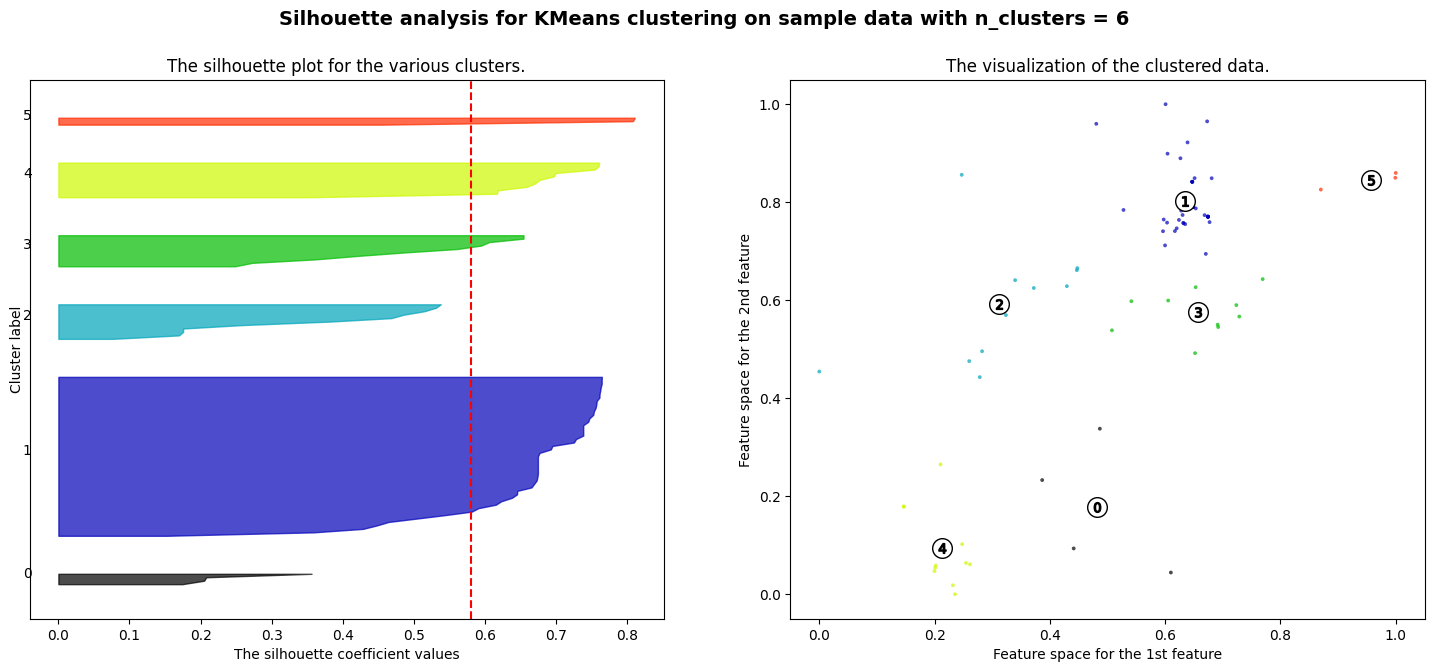

In [18]:
range_n_clusters = [2, 3, 4, 5, 6]

for n_clusters in range_n_clusters:
    # Erstelle eine Grafik mit 1 Zeile und 2 Spalten
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    # Die erste Grafik ist der Silhouette-Plot
    # Der Silhouette-Koeffizient liegt zwischen -1 und 1, in diesem Beispiel aber
    # immer innerhalb von [-0.1, 1]
    #ax1.set_xlim([-0.1, 1])
    # (n_clusters+1)*10 fügt Leerraum zwischen den Silhouette-Plots der
    # einzelnen Cluster ein, um sie klar voneinander abzugrenzen.
    ax1.set_ylim([0, len(x_scaled) + (n_clusters + 1) * 10])

    # Initialisiere das Modell mit n_clusters Clustern und dem Zufalls-Seed 10,
    # damit das Ergebnis reproduzierbar ist.
    clusterer = KMeans(n_clusters=n_clusters, random_state=10, n_init = 'auto')
    cluster_labels = clusterer.fit_predict(x_scaled)

    # silhouette_score liefert den Durchschnitt über alle Beobachtungen.
    # Er zeigt, wie dicht und wie klar getrennt die gebildeten Cluster sind
    silhouette_avg = silhouette_score(x_scaled, cluster_labels)
    print(
        "For n_clusters =",
        n_clusters,
        "The average silhouette_score is :",
        silhouette_avg,
    )

    # Berechne den Silhouette-Wert jeder Beobachtung
    sample_silhouette_values = silhouette_samples(x_scaled, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Sammle die Silhouette-Werte der Beobachtungen in
        # Cluster i und sortiere sie
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]

        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Beschrifte die Silhouette-Plots in der Mitte mit der Nummer des Clusters
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Berechne y_lower für den nächsten Plot
        y_lower = y_upper + 10  # 10 Einheiten Abstand

    ax1.set_title("The silhouette plot for the various clusters.")
    ax1.set_xlabel("The silhouette coefficient values")
    ax1.set_ylabel("Cluster label")

    # Senkrechte Linie für den durchschnittlichen Silhouette-Score aller Werte
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])  # Entferne die Beschriftung der y-Achse
    #ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    # Die zweite Grafik zeigt die gebildeten Cluster
    colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(
        #x[:, 0], x[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
        x_scaled.iloc[:, 0], x_scaled.iloc[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
    )

    # Beschrifte die Cluster
    centers = clusterer.cluster_centers_
    # Zeichne weiße Kreise in die Clusterzentren
    ax2.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="o",
        c="white",
        alpha=1,
        s=200,
        edgecolor="k",
    )

    for i, c in enumerate(centers):
        ax2.scatter(c[0], c[1], marker="$%d$" % i, alpha=1, s=50, edgecolor="k")

    ax2.set_title("The visualization of the clustered data.")
    ax2.set_xlabel("Feature space for the 1st feature")
    ax2.set_ylabel("Feature space for the 2nd feature")

    plt.suptitle(
        "Silhouette analysis for KMeans clustering on sample data with n_clusters = %d"
        % n_clusters,
        fontsize=14,
        fontweight="bold",
    )

plt.show()

Die Ausgabe enthält für jede Anzahl an Clustern den durchschnittlichen Silhouette-Koeffizienten und eine Grafik.

* **Linke Grafik:** Jeder Balken ist eine Destillerie, gruppiert nach Cluster. Werte nahe 1 bedeuten, dass die Beobachtung gut in ihr Cluster passt und weit vom nächsten Cluster entfernt ist. Werte nahe 0 liegen an der Grenze zwischen zwei Clustern, negative Werte deuten auf eine falsche Zuordnung hin. Die rote Linie ist der Durchschnitt.
* **Rechte Grafik:** die Destillerien im (skalierten) Koordinatenraum, eingefärbt nach Cluster, mit den Clusterzentren als nummerierte Kreise.

Der durchschnittliche Silhouette-Koeffizient ist bei 2 Clustern am höchsten (0,69), gefolgt von 3 (0,59) und 6 Clustern (0,58). Nach diesem Kriterium wäre die Aufteilung in Südwesten und Rest die klarste. Bei mehr Clustern gibt es zunehmend Destillerien mit niedrigen oder negativen Werten, also Beobachtungen, die zwischen zwei Clustern liegen.

In [19]:
# Zur Kontrolle: die skalierten Koordinaten aus Exkurs B
x_scaled

,Longitude,Latitude
0,0.429495,0.628686
1,0.633648,0.785012
2,0.626505,0.889675
3,0.202110,0.058504
4,0.604132,0.899072
...,...,...
81,0.441341,0.093458
82,0.605209,0.599355
83,0.596264,0.740819
84,0.616923,0.741134


## DBSCAN

k-means und hierarchisches Clustering ordnen *jede* Beobachtung einem Cluster zu, und bei k-means muss die Anzahl der Cluster vorab festgelegt werden. **DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*) geht anders vor: Ein Cluster ist ein Bereich, in dem die Beobachtungen dicht beieinander liegen. Der Algorithmus braucht dafür zwei Parameter:

* `eps`: der Radius, innerhalb dessen zwei Beobachtungen als Nachbarn gelten,
* `min_samples`: die Mindestanzahl an Beobachtungen (inklusive der Beobachtung selbst) innerhalb von `eps`, damit eine Beobachtung als *Kernpunkt* gilt.

Kernpunkte, die innerhalb von `eps` zueinander liegen, bilden gemeinsam einen Cluster. Beobachtungen in der Nähe eines Kernpunkts, die selbst kein Kernpunkt sind, werden als *Randpunkte* dem Cluster zugeordnet. Alle übrigen Beobachtungen gelten als *Rauschen* und erhalten das Label `-1`. Die Anzahl der Cluster ergibt sich also aus den Daten, und Cluster können beliebige Formen annehmen.

Wir wenden DBSCAN auf die Standorte der Destillerien an. Die ursprünglichen Koordinaten im Datensatz sind im britischen Koordinatensystem (EPSG:27700) in Metern angegeben. Rechnen wir sie in Kilometer um, lässt sich `eps` direkt als Entfernung interpretieren. Deshalb verzichten wir hier auf die Normalisierung.

In [20]:
# Koordinaten in Kilometern (EPSG:27700 ist in Metern angegeben)
x_geo = df[['Latitude', 'Longitude']] / 1000

x_geo.head()

,Latitude,Longitude
0,286.58,749.68
1,326.34,842.57
2,352.96,839.32
3,141.56,646.22
4,355.35,829.14


### Wahl von `eps`

Eine gängige Heuristik für die Wahl von `eps` ist der *k-Distanz-Plot*: Für jede Beobachtung berechnen wir die Entfernung zu ihrem `min_samples`-nächsten Nachbarn (die Beobachtung selbst zählt mit) und sortieren diese Entfernungen der Größe nach. Ein geeigneter Wert für `eps` liegt dort, wo die Kurve deutlich ansteigt.

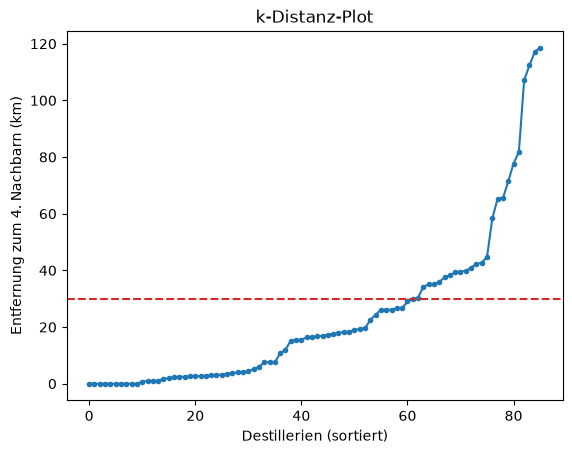

In [21]:
min_samples = 4

# Berechne für jede Beobachtung die Entfernungen zu den nächsten Nachbarn
nn = NearestNeighbors(n_neighbors = min_samples)
nn.fit(x_geo)
distances, _ = nn.kneighbors(x_geo)

# Sortiere die Entfernung zum min_samples-nächsten Nachbarn
k_dist = np.sort(distances[:, min_samples - 1])

plt.plot(k_dist, marker = '.')
plt.axhline(30, color = "tab:red", linestyle = "--")
plt.title('k-Distanz-Plot')
plt.xlabel('Destillerien (sortiert)')
plt.ylabel('Entfernung zum ' + str(min_samples) + '. Nachbarn (km)')
plt.show()

Bis etwa 30 km steigt die Kurve flach an, danach wird sie steiler, und ab etwa 45 km folgen nur noch wenige, abgelegene Destillerien. Wir wählen `eps = 30` (km) und nehmen in Kauf, dass etwas mehr Destillerien als Rauschen gelten.

### Training

In [22]:
# Erstelle ein 'leeres' Modell
dbscan = DBSCAN(eps = 30, min_samples = min_samples)

# Trainiere das Modell und weise jeder Destillerie ein Label zu
pred_dbscan = dbscan.fit_predict(x_geo)

# Anzahl der Destillerien je Cluster (-1 = Rauschen)
pd.Series(pred_dbscan).value_counts().sort_index()

-1    15
 0     9
 1    54
 2     8
Name: count, dtype: int64

Anders als bei k-means gibt es keine Methode `predict`, weil DBSCAN keine Clusterzentren schätzt, mit denen neue Beobachtungen zugeordnet werden könnten. Deshalb verwenden wir `fit_predict`.

### Visualisierung

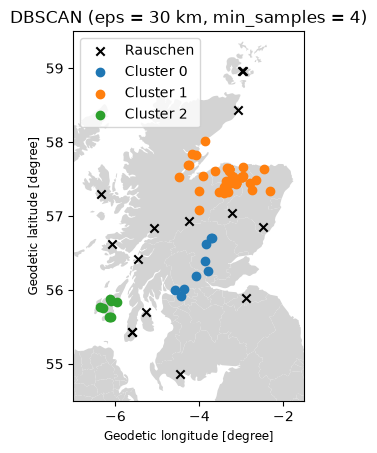

In [23]:
# Plotte Landkarte von UK
ctry.plot(color = "lightgrey")

# Rauschen (Label -1) in Schwarz
noise = pred_dbscan == -1
plt.scatter(x = coords_new.loc[noise, 'Longitude'], y = coords_new.loc[noise, 'Latitude'],
            marker = 'x', c = "black", label = "Rauschen")

# Cluster in Farbe
for label in sorted(set(pred_dbscan) - {-1}):
    sel = pred_dbscan == label
    plt.scatter(x = coords_new.loc[sel, 'Longitude'], y = coords_new.loc[sel, 'Latitude'],
                marker = 'o', label = "Cluster " + str(label))

# Trimme die Grafik
plt.axis([-7, -1.5, 54.5, 59.5])
plt.legend(loc = "upper left")
plt.title("DBSCAN (eps = 30 km, min_samples = " + str(min_samples) + ")")
plt.show()

DBSCAN findet die dichten Regionen mit vielen Destillerien, darunter die Speyside mit den umliegenden Highlands als größten Cluster, eine Gruppe in Zentralschottland und die Insel Islay, ohne dass wir die Anzahl der Cluster vorgeben mussten. Abgelegene Destillerien, etwa auf den Orkney-Inseln oder an der Westküste, werden nicht in einen Cluster gezwungen, sondern als Rauschen markiert. Das Ergebnis hängt allerdings stark von `eps` und `min_samples` ab: Ein kleineres `eps` zerlegt die Daten in mehr und kleinere Cluster mit mehr Rauschen, ein größeres `eps` verschmilzt benachbarte Regionen. Probiere verschiedene Werte aus!

## DENCLUE

**DENCLUE** (*DENsity-based CLUstEring*) ist wie DBSCAN ein dichtebasiertes Verfahren, beschreibt die Dichte aber nicht über Nachbarn innerhalb eines festen Radius, sondern über eine glatte Dichtefunktion:

1. **Dichte schätzen:** Um jede Beobachtung legen wir eine Glockenkurve (Gauß-Kernel) mit Bandbreite $h$. Die Dichte an einem Punkt $p$ ist die Summe dieser Kurven:
$$f(p) = \sum_{i=1}^{n} \exp\left(-\frac{\lVert p - x_i \rVert^2}{2h^2}\right)$$
Jede Beobachtung in unmittelbarer Nähe von $p$ trägt fast 1 bei, weit entfernte Beobachtungen fast 0. $f(p)$ lässt sich also als „gewichtete Anzahl der Beobachtungen in der Nähe von $p$“ lesen.
2. **Bergsteigen (*Hill Climbing*):** Von jeder Beobachtung aus gehen wir schrittweise bergauf, bis wir ein lokales Maximum der Dichte erreichen. Dieses Maximum heißt **Dichte-Attraktor**.
3. **Cluster bilden:** Beobachtungen, die beim selben Attraktor ankommen, bilden einen Cluster. Ist die Dichte am Attraktor kleiner als ein Schwellenwert $\xi$ (*xi*), gelten die Beobachtungen als Rauschen.

Die beiden Parameter sind also die Bandbreite $h$ (wie glatt die Dichte ist) und der Schwellenwert $\xi$ (wie dicht ein Cluster mindestens sein muss).

`scikit-learn` enthält kein DENCLUE. Der Algorithmus ist aber kurz genug, um ihn selbst zu programmieren. Wir verwenden dieselben Koordinaten in Kilometern wie bei DBSCAN (`x_geo`).

In [24]:
def denclue_density(p, X, h):
    """Dichte am Punkt p: Summe der Gauß-Kernel um alle Beobachtungen in X."""
    squared_dist = ((X - p) ** 2).sum(axis = 1)
    return np.exp(-squared_dist / (2 * h ** 2)).sum()

def hill_climb(p, X, h, tol = 1e-4, max_iter = 1000):
    """Gehe von p aus bergauf, bis der Dichte-Attraktor erreicht ist."""
    for _ in range(max_iter):
        # Gewicht jeder Beobachtung: je näher an p, desto größer
        weights = np.exp(-((X - p) ** 2).sum(axis = 1) / (2 * h ** 2))
        # Neuer Punkt: gewichteter Mittelwert aller Beobachtungen (ein Schritt bergauf)
        p_new = (weights[:, None] * X).sum(axis = 0) / weights.sum()
        # Aufhören, wenn sich der Punkt kaum noch bewegt
        if np.linalg.norm(p_new - p) < tol:
            return p_new
        p = p_new
    return p

Der Schritt in `hill_climb` verschiebt den Punkt zum gewichteten Mittelwert der Beobachtungen, wobei nahe Beobachtungen stärker zählen. Dieser Schritt führt bei einem Gauß-Kernel immer bergauf (das Verfahren ist auch als *Mean Shift* bekannt).

Nun führen wir das Bergsteigen für jede Destillerie durch. Als Bandbreite wählen wir $h = 15$ km.

In [25]:
h = 15 # Bandbreite in km
X_geo = x_geo.to_numpy()

# Finde für jede Destillerie ihren Dichte-Attraktor
attractors = np.array([hill_climb(x_i, X_geo, h) for x_i in X_geo])

# Runde auf ganze km: Destillerien mit demselben Attraktor haben dann exakt dieselben Koordinaten
attractors = attractors.round(0)
unique_attractors, attractor_id = np.unique(attractors, axis = 0, return_inverse = True)

# Dichte an jedem Attraktor und Anzahl der Destillerien, die dort ankommen
attractor_table = pd.DataFrame({
    'Dichte': [denclue_density(a, X_geo, h) for a in unique_attractors],
    'Destillerien': np.bincount(attractor_id)
}).round(2)
attractor_table.sort_values('Dichte', ascending = False)

,Dichte,Destillerien
12,28.47,48
1,5.54,8
8,3.76,6
11,2.94,3
7,2.77,3
10,2.29,3
3,2.16,3
15,1.99,2
9,1.65,2
2,1.02,1


Das Bergsteigen endet an 17 verschiedenen Attraktoren. Der Attraktor mit der weitaus höchsten Dichte (rund 28) zieht 48 Destillerien an, das ist die Speyside. Danach folgen einige Attraktoren mit mittlerer Dichte zwischen etwa 1,6 und 5,5, die jeweils 2 bis 8 Destillerien anziehen. Am Ende stehen mehrere Attraktoren mit einer Dichte von etwa 1: Das sind Destillerien, die allein liegen und deren Dichte fast nur aus ihrem eigenen Beitrag (1) besteht.

Als Schwellenwert wählen wir $\xi = 2{,}5$: Ein Cluster muss am Attraktor mindestens die Dichte von zweieinhalb Destillerien in unmittelbarer Nähe haben.

In [26]:
xi = 2.5 # Schwellenwert für die Dichte am Attraktor

# Attraktoren mit ausreichender Dichte bilden Cluster, nummeriert nach absteigender Dichte
dense = attractor_table[attractor_table['Dichte'] >= xi].sort_values('Dichte', ascending = False)
cluster_of_attractor = {a: k for k, a in enumerate(dense.index)}

# Label jeder Destillerie: Cluster ihres Attraktors oder -1 für Rauschen
pred_denclue = np.array([cluster_of_attractor.get(a, -1) for a in attractor_id])

# Anzahl der Destillerien je Cluster (-1 = Rauschen)
pd.Series(pred_denclue).value_counts().sort_index()

-1    18
 0    48
 1     8
 2     6
 3     3
 4     3
Name: count, dtype: int64

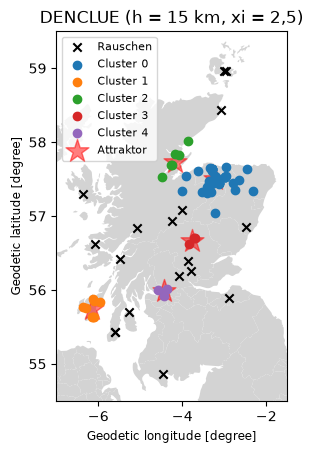

In [27]:
# Rechne die Attraktoren für die Karte in Längen- und Breitengrade um (Koordinaten in Metern)
attr_lon, attr_lat = transformer.transform(unique_attractors[dense.index, 0] * 1000,
                                           unique_attractors[dense.index, 1] * 1000)

# Plotte Landkarte von UK
ctry.plot(color = "lightgrey")

# Rauschen (Label -1) in Schwarz
noise = pred_denclue == -1
plt.scatter(x = coords_new.loc[noise, 'Longitude'], y = coords_new.loc[noise, 'Latitude'],
            marker = 'x', c = "black", label = "Rauschen")

# Cluster in Farbe
for label in sorted(set(pred_denclue) - {-1}):
    sel = pred_denclue == label
    plt.scatter(x = coords_new.loc[sel, 'Longitude'], y = coords_new.loc[sel, 'Latitude'],
                marker = 'o', label = "Cluster " + str(label), zorder = 3)

# Dichte-Attraktoren als Sterne (hinter den Punkten)
plt.scatter(attr_lon, attr_lat, marker = '*', s = 300, c = "red", alpha = 0.5, label = "Attraktor", zorder = 2)

# Trimme die Grafik
plt.axis([-7, -1.5, 54.5, 59.5])
plt.legend(loc = "upper left", fontsize = 8)
plt.title("DENCLUE (h = 15 km, xi = 2,5)")
plt.show()

DENCLUE findet fünf Cluster: die Speyside (48 Destillerien), Islay (8), eine Gruppe nördlich von Inverness am Cromarty und Dornoch Firth (6) sowie zwei kleine Gruppen mit je 3 Destillerien in Perthshire und nördlich von Glasgow. 18 Destillerien gelten als Rauschen. Die roten Sterne (hinter den Punkten) markieren die Dichte-Attraktoren, also die „Gipfel“ der Dichte, zu denen die Destillerien eines Clusters hinaufsteigen.

**Vergleich mit DBSCAN:**

* DBSCAN hat die Speyside und die Gruppe nördlich von Inverness zu einem großen Cluster verbunden, weil eine Kette von Destillerien mit Abständen unter 30 km die beiden Regionen verbindet. Bei DENCLUE liegt zwischen den beiden Regionen ein Tal in der Dichte, deshalb steigen die Destillerien zu verschiedenen Gipfeln auf.
* Jeder Cluster hat bei DENCLUE ein Zentrum (den Attraktor). Neue Beobachtungen könnte man deshalb einem Cluster zuordnen, indem man auch von ihnen aus bergauf geht.
* Wie bei DBSCAN hängt das Ergebnis stark von den Parametern ab: Mit größerem $h$ wird die Dichte glatter, und benachbarte Gipfel verschmelzen. Ein kleineres $\xi$ macht aus mehr kleinen Gruppen eigene Cluster.

*Hinweis:* Das ursprüngliche DENCLUE verbindet zusätzlich Attraktoren, zwischen denen ein Weg mit Dichte über $\xi$ existiert. Diesen Schritt lassen wir hier der Einfachheit halber weg.

## Netzwerkanalyse

Bisher haben wir Beobachtungen anhand ihrer Merkmale analysiert. Oft liegen Daten aber als **Netzwerk** vor: Knoten (z. B. Personen, Webseiten, Unternehmen) und Kanten zwischen ihnen (Freundschaften, Links, Geschäftsbeziehungen). Das Paket `networkx` enthält viele Funktionen für die Arbeit mit Netzwerken.

### Ein Netzwerk der Whiskys

Die Whisky-Daten sind kein Netzwerk, wir können aber eines daraus bauen: Wir verbinden jede Destillerie mit den 5 Destillerien, deren Geschmacksprofil ihr am ähnlichsten ist (*k-Nearest-Neighbour-Graph*). Dafür verwenden wir dieselben skalierten Geschmacksmerkmale wie für k-means. Das Netzwerk ist **gerichtet**: Eine Kante von A nach B bedeutet „B gehört zu den 5 ähnlichsten Whiskys von A“, das muss umgekehrt nicht gelten.

In [28]:
# Geschmacksmerkmale wie im Abschnitt zu k-means
x_taste = df.drop(columns = ['RowID', 'Distillery', 'Postcode', 'Longitude', 'Latitude', 'Fruity', 'Sweetness'])
x_taste_scaled = preprocessing.MinMaxScaler().fit_transform(x_taste)

# Adjazenzmatrix: Zeile i hat eine 1 bei den 5 ähnlichsten Destillerien von Destillerie i
A_knn = kneighbors_graph(x_taste_scaled, n_neighbors = 5, include_self = False).toarray()

# Erstelle daraus ein gerichtetes networkx-Netzwerk
G_knn = nx.from_numpy_array(A_knn, create_using = nx.DiGraph)
print("Anzahl der Knoten:", G_knn.number_of_nodes())
print("Anzahl der Kanten:", G_knn.number_of_edges())

Anzahl der Knoten: 86
Anzahl der Kanten: 430


Das Netzwerk hat 86 Knoten (Destillerien) und 86 × 5 = 430 gerichtete Kanten, weil jede Destillerie genau 5 Nachbarn auswählt. Wie oft eine Destillerie *von anderen* als Nachbar ausgewählt wird, ist dagegen unterschiedlich.

### PageRank

PageRank wurde von den Gründern von Google entwickelt, um die Bedeutung von Webseiten zu bewerten. Die Idee: Eine Seite ist wichtig, wenn viele *wichtige* Seiten auf sie verlinken. Man kann sich das als zufälligen Surfer vorstellen:

* Er startet auf einer zufälligen Seite und folgt mit Wahrscheinlichkeit 0,85 einem zufälligen Link auf der aktuellen Seite.
* Mit Wahrscheinlichkeit 0,15 springt er stattdessen auf eine völlig zufällige Seite (Parameter `alpha = 0.85`, der *Dämpfungsfaktor*).

Der PageRank einer Seite ist der Anteil der Zeit, den der Surfer auf lange Sicht auf dieser Seite verbringt. Die Werte aller Knoten summieren sich daher zu 1.

In unserem Netzwerk „surft“ man von einem Whisky zu einem seiner ähnlichsten Whiskys. Ein hoher PageRank bedeutet also: Dieser Whisky wird oft als ähnlich genannt, und zwar von Whiskys, die selbst oft genannt werden.

In [29]:
# Berechne den PageRank jedes Knotens
pagerank = pd.Series(nx.pagerank(G_knn, alpha = 0.85))

# Stelle das Ergebnis mit den Namen der Destillerien und der Anzahl eingehender Kanten zusammen
pr = pd.DataFrame({'Distillery': df['Distillery'],
                   'PageRank': pagerank,
                   'Eingehende Kanten': A_knn.sum(axis = 0)}) # Spaltensumme = wie oft als Nachbar gewählt
pr = pr.sort_values('PageRank', ascending = False)

# Die 10 Destillerien mit dem höchsten PageRank
pr.head(10)

,Distillery,PageRank,Eingehende Kanten
41,Glenallachie,0.042587,15.0
52,Glenturret,0.040551,14.0
15,Benromach,0.039897,16.0
22,Cardhu,0.038111,11.0
60,Loch Lomond,0.036251,13.0
0,Aberfeldy,0.032397,11.0
81,Tobermory,0.030644,9.0
17,BlairAthol,0.029896,11.0
63,Mannochmore,0.026101,13.0
49,Glenlossie,0.025349,8.0


In [30]:
# Die 8 Destillerien mit dem niedrigsten PageRank
pr.tail(8)

,Distillery,PageRank,Eingehende Kanten
4,Ardmore,0.002391,1.0
61,Longmorn,0.002226,1.0
42,Glendronach,0.002153,1.0
65,Mortlach,0.002041,1.0
10,Balmenach,0.001744,0.0
1,Aberlour,0.001744,0.0
34,GlenGarioch,0.001744,0.0
80,Teaninich,0.001744,0.0


Bei 86 Destillerien läge der durchschnittliche PageRank bei 1/86 ≈ 0,012. Glenallachie, Glenturret und Benromach erreichen rund 0,04, also mehr als das Dreifache. Sie werden von 14 bis 16 anderen Destillerien als ähnlich genannt. Ihre Geschmacksprofile sind ausgewogen, mit mittleren Werten bei fast allen Merkmalen: Sie sind gewissermaßen die „typischen“ schottischen Whiskys.

Am unteren Ende stehen Destillerien, die kaum oder nie als Nachbar gewählt werden. Aberlour, Balmenach, Glen Garioch und Teaninich haben keine einzige eingehende Kante. Ihr PageRank von 0,0017 entspricht genau dem Anteil, den sie allein durch die zufälligen Sprünge erhalten (0,15/86). Diese Whiskys haben ein eigenständiges Profil, das keinem anderen sehr nahe kommt.

PageRank und die Anzahl der eingehenden Kanten hängen eng zusammen, sind aber nicht dasselbe: Benromach hat die meisten eingehenden Kanten (16), steht aber nur auf Platz 3, weil die Kanten von weniger zentralen Whiskys kommen.

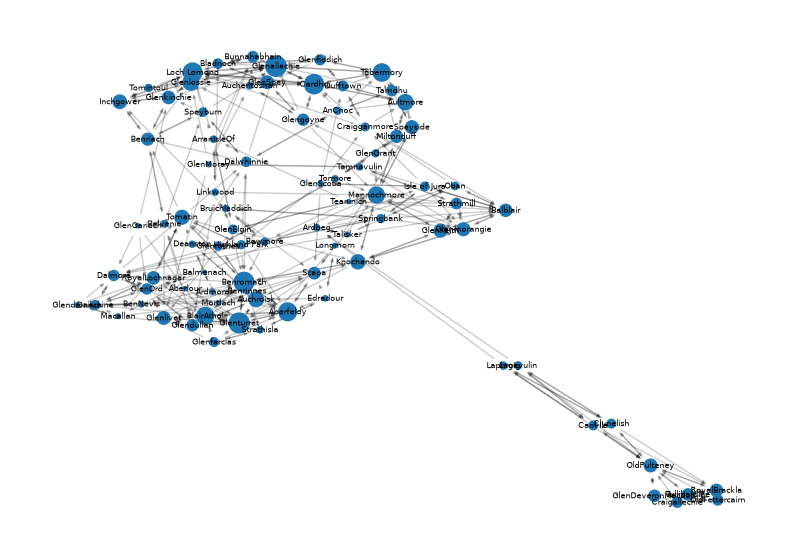

In [31]:
# Zeichne das Netzwerk: Größe der Knoten proportional zum PageRank
pos_knn = nx.spring_layout(G_knn, seed = 0) # Positionen: verbundene Knoten liegen nahe beieinander

plt.figure(figsize = (10, 7))
nx.draw_networkx_edges(G_knn, pos_knn, alpha = 0.2, arrowsize = 5)
nx.draw_networkx_nodes(G_knn, pos_knn, node_size = pagerank * 5000, node_color = "tab:blue")
nx.draw_networkx_labels(G_knn, pos_knn, labels = dict(enumerate(df['Distillery'])), font_size = 6)
plt.axis("off")
plt.show()

Die großen Knoten mit hohem PageRank liegen im dicht vernetzten Zentrum des Netzwerks. Kleine Knoten am Rand sind Whiskys mit ungewöhnlichem Profil. Etwas abseits liegt eine eigene Gruppe, die vor allem untereinander verbunden ist: die Whiskys mit Tabaknote. Diese Gruppen schauen wir uns im nächsten Abschnitt genauer an.

## Stochastic Block Model

Auch in Netzwerken können wir nach Clustern suchen: Gruppen von Knoten, die ähnlich vernetzt sind.

Das **Stochastic Block Model** (SBM) ist ein Wahrscheinlichkeitsmodell für solche Netzwerke:

* Jeder Knoten gehört zu genau einem von $K$ Blöcken (Clustern).
* Die Wahrscheinlichkeit, dass zwischen zwei Knoten eine Kante besteht, hängt *nur* von den Blöcken der beiden Knoten ab. Sie steht in einer $K \times K$-Matrix $P$: $P_{rs}$ ist die Wahrscheinlichkeit für eine Kante zwischen einem Knoten aus Block $r$ und einem Knoten aus Block $s$.

Sind die Werte auf der Diagonale von $P$ groß und die übrigen klein, sind die Knoten innerhalb eines Blocks dicht vernetzt und zwischen den Blöcken kaum (*Communities*). Das SBM kann aber auch andere Strukturen abbilden, etwa Blöcke, deren Knoten vor allem mit Knoten aus *anderen* Blöcken verbunden sind.

Wir gehen in zwei Schritten vor: Zuerst simulieren wir ein Netzwerk aus einem SBM, dessen Blöcke wir kennen, und prüfen, ob wir sie wiederfinden. Danach wenden wir das Modell auf das Whisky-Netzwerk an.

### Simulation eines Netzwerks

Das Paket `networkx` enthält Funktionen für die Arbeit mit Netzwerken, darunter `stochastic_block_model`, das ein zufälliges Netzwerk aus einem SBM erzeugt.

In [32]:
# Drei Blöcke mit je 30 Knoten
sizes = [30, 30, 30]

# Kantenwahrscheinlichkeiten: 30 % innerhalb eines Blocks, 2 % zwischen den Blöcken
P = [[0.30, 0.02, 0.02],
     [0.02, 0.30, 0.02],
     [0.02, 0.02, 0.30]]

# Simuliere das Netzwerk (seed macht das Ergebnis reproduzierbar)
G = nx.stochastic_block_model(sizes, P, seed = 0)

# Die wahren Blöcke der Knoten: die ersten 30 Knoten in Block 0, die nächsten 30 in Block 1 usw.
blocks_true = np.repeat([0, 1, 2], sizes)

print("Anzahl der Knoten:", G.number_of_nodes())
print("Anzahl der Kanten:", G.number_of_edges())

Anzahl der Knoten: 90
Anzahl der Kanten: 445


Ein Netzwerk lässt sich als **Adjazenzmatrix** $A$ darstellen: $A_{ij} = 1$, wenn zwischen Knoten $i$ und $j$ eine Kante besteht, sonst 0. In der linken Grafik sind die Knoten nach ihren Blöcken sortiert. In der Praxis kennen wir die Blöcke aber nicht, und die Knoten liegen in beliebiger Reihenfolge vor. Das zeigt die rechte Grafik, in der wir die Reihenfolge der Knoten zufällig vertauscht haben.

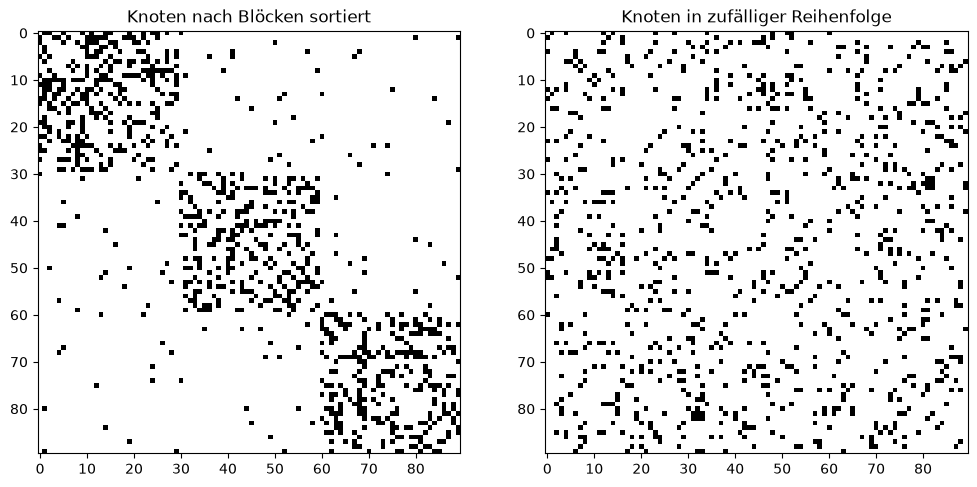

In [33]:
# Adjazenzmatrix als NumPy-Array
A = nx.to_numpy_array(G)

# Vertausche die Reihenfolge der Knoten zufällig
rng = np.random.default_rng(0)
order = rng.permutation(len(A))
A_perm = A[np.ix_(order, order)] # Zeilen und Spalten in der neuen Reihenfolge
blocks_true_perm = blocks_true[order]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 6))
ax1.imshow(A, cmap = "Greys")
ax1.set_title("Knoten nach Blöcken sortiert")
ax2.imshow(A_perm, cmap = "Greys")
ax2.set_title("Knoten in zufälliger Reihenfolge")
plt.show()

Das Netzwerk hat 90 Knoten und 445 Kanten. Links sind die drei Blöcke als dunkle Quadrate auf der Diagonale gut zu erkennen: Innerhalb der Blöcke gibt es viele Kanten, dazwischen nur vereinzelte Punkte. Rechts enthält die Matrix genau dieselben Kanten, aber die Struktur ist nicht mehr zu sehen. Aufgabe der Schätzung ist es, die Blöcke aus dieser ungeordneten Matrix wiederzufinden.

### Schätzung der Blöcke

Um ein SBM zu schätzen, müssen wir die Blockzugehörigkeit der Knoten und die Matrix $P$ bestimmen. Für die Blöcke verwenden wir **Spectral Clustering**: Das Verfahren berechnet aus der Adjazenzmatrix für jeden Knoten einige Koordinaten (aus den Eigenvektoren der Matrix) und gruppiert die Knoten anschließend mit k-means. Für Netzwerke, die aus einem SBM stammen, findet es die Blöcke zuverlässig, wenn die Blöcke ausreichend dicht vernetzt sind. Mit `affinity = 'precomputed'` teilen wir `scikit-learn` mit, dass wir direkt die Adjazenzmatrix übergeben.

Wie bei k-means müssen wir die Anzahl der Blöcke vorgeben.

In [34]:
# Erstelle ein 'leeres' Modell mit 3 Blöcken
spectral = SpectralClustering(n_clusters = 3, affinity = 'precomputed', random_state = 0)

# Schätze die Blöcke aus der ungeordneten Adjazenzmatrix
blocks_est = spectral.fit_predict(A_perm)

# Vergleiche wahre (Zeilen) und geschätzte Blöcke (Spalten)
pd.crosstab(blocks_true_perm, blocks_est, rownames = ['wahr'], colnames = ['geschätzt'])

geschätzt,0,1,2
wahr,,,
0,0,30,0
1,30,0,0
2,0,0,30


Jeder wahre Block landet vollständig in genau einem geschätzten Block: Alle 90 Knoten werden richtig zugeordnet. Dass die Nummern der Blöcke nicht übereinstimmen (z. B. wahrer Block 0 = geschätzter Block 2), spielt keine Rolle, denn die Nummerierung von Clustern ist immer willkürlich.

Ein Maß, das diese Umbenennung berücksichtigt, ist der **Adjusted Rand Index** (ARI). Er ist 1 bei perfekter Übereinstimmung und liegt bei zufälliger Zuordnung um 0.

In [35]:
adjusted_rand_score(blocks_true_perm, blocks_est)

1.0

Mit den geschätzten Blöcken können wir auch die Matrix $P$ schätzen: Für jedes Paar von Blöcken teilen wir die Anzahl der vorhandenen Kanten durch die Anzahl der möglichen Kanten.

In [36]:
def block_matrix(A, blocks):
    """Schätze die Kantenwahrscheinlichkeiten zwischen den Blöcken."""
    K = blocks.max() + 1
    P_est = np.zeros((K, K))
    for r in range(K):
        for s in range(K):
            in_r = blocks == r
            in_s = blocks == s
            # Anzahl der Kanten zwischen Block r und Block s
            edges = A[np.ix_(in_r, in_s)].sum()
            # Anzahl der möglichen Kanten (innerhalb eines Blocks ohne Kanten eines Knotens zu sich selbst)
            possible = in_r.sum() * in_s.sum() - (in_r.sum() if r == s else 0)
            P_est[r, s] = edges / possible
    return pd.DataFrame(P_est).round(3)

block_matrix(A_perm, blocks_est)

,0,1,2
0,0.292,0.023,0.018
1,0.023,0.326,0.016
2,0.018,0.016,0.287


Die geschätzten Wahrscheinlichkeiten liegen nahe an den wahren Werten: knapp 0,3 innerhalb der Blöcke und rund 0,02 zwischen den Blöcken. Die Abweichungen entstehen durch den Zufall bei der Simulation. Die Reihenfolge der Zeilen und Spalten folgt der Nummerierung der geschätzten Blöcke.

### Anwendung: ein Netzwerk der Whiskys

Nun suchen wir im Whisky-Netzwerk aus dem Abschnitt zu PageRank nach Blöcken. Das SBM in dieser einfachen Form ist für ungerichtete Netzwerke gedacht. Deshalb verbinden wir zwei Destillerien, sobald mindestens eine die andere als Nachbarn hat, und suchen dann drei Blöcke.

In [37]:
# Mache das Netzwerk ungerichtet: Eine Kante besteht, wenn mindestens eine der beiden
# Destillerien die andere als Nachbarn hat
A_whisky = np.maximum(A_knn, A_knn.T)

# Erstelle daraus ein ungerichtetes networkx-Netzwerk
G_whisky = nx.from_numpy_array(A_whisky)
print("Anzahl der Knoten:", G_whisky.number_of_nodes())
print("Anzahl der Kanten:", G_whisky.number_of_edges())
print("Zusammenhängende Teilnetzwerke:", nx.number_connected_components(G_whisky))

Anzahl der Knoten: 86
Anzahl der Kanten: 309
Zusammenhängende Teilnetzwerke: 1


In [38]:
# Schätze drei Blöcke
spectral_whisky = SpectralClustering(n_clusters = 3, affinity = 'precomputed', random_state = 0)
blocks_whisky = spectral_whisky.fit_predict(A_whisky)

# Anzahl der Destillerien je Block
pd.Series(blocks_whisky).value_counts().sort_index()

0    33
1    43
2    10
Name: count, dtype: int64

Das ungerichtete Netzwerk hat 86 Knoten und 309 Kanten und ist zusammenhängend: Von jeder Destillerie aus kann man über Kanten jede andere erreichen. Es hat weniger als 430 Kanten, weil zwei Destillerien, die sich gegenseitig als Nachbarn haben, nur eine gemeinsame Kante bekommen. Die drei Blöcke haben 33, 43 und 10 Destillerien.

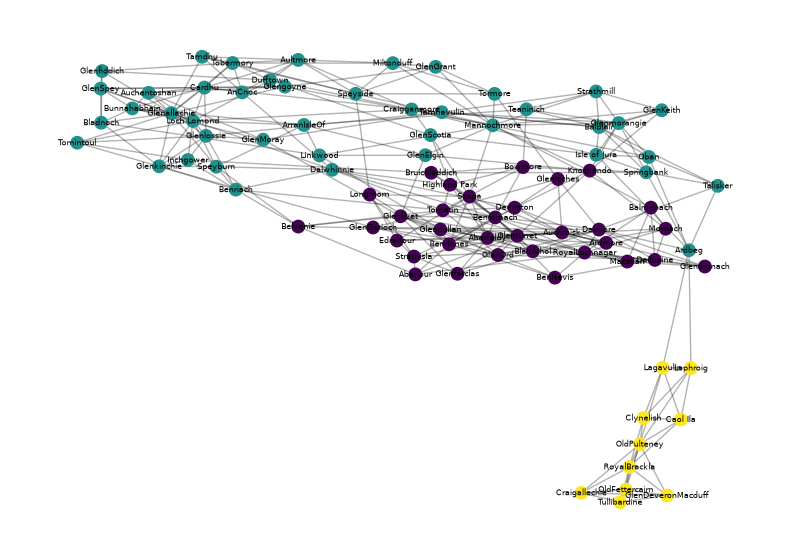

In [39]:
# Zeichne das Netzwerk, eingefärbt nach Block
pos = nx.spring_layout(G_whisky, seed = 0) # Positionen der Knoten: verbundene Knoten liegen nahe beieinander

plt.figure(figsize = (10, 7))
nx.draw_networkx_edges(G_whisky, pos, alpha = 0.3)
nx.draw_networkx_nodes(G_whisky, pos, node_color = blocks_whisky, cmap = "viridis", node_size = 80)
nx.draw_networkx_labels(G_whisky, pos, labels = dict(enumerate(df['Distillery'])), font_size = 6)
plt.axis("off")
plt.show()

In [40]:
# Geschätzte Kantenwahrscheinlichkeiten zwischen den Blöcken
block_matrix(A_whisky, blocks_whisky)

,0,1,2
0,0.216,0.019,0.000
1,0.019,0.154,0.005
2,0.000,0.005,0.600


In [41]:
# Durchschnittliches Geschmacksprofil je Block (Originalskala 0 bis 4)
x_taste.groupby(blocks_whisky).mean().round(2)

,Body,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral
0,2.55,1.61,0.18,0.0,1.82,1.67,1.70,1.76,2.06,1.67
1,1.60,1.28,0.56,0.0,0.95,1.14,0.42,1.30,1.63,1.84
2,2.50,2.40,1.70,1.0,0.60,1.50,1.00,1.20,1.70,1.20


Die Blöcke lassen sich über ihr durchschnittliches Geschmacksprofil interpretieren:

* **Block 2** enthält genau die 10 Destillerien mit Tabaknote (`Tobacco` = 1), darunter Caol Ila, Lagavulin und Laphroaig. Da `Tobacco` nur die Werte 0 und 1 hat, liegen diese Whiskys nach der Skalierung weit von allen anderen entfernt. Innerhalb dieses Blocks ist das Netzwerk sehr dicht (Kantenwahrscheinlichkeit 0,6), zu Block 1 gibt es nur vereinzelte und zu Block 0 gar keine Kanten.
* **Block 0** enthält vollmundige Whiskys mit mehr Weinnote, Honig und Nussigkeit (`Body` 2,6, `Winey` 1,7).
* **Block 1** enthält leichtere Whiskys (`Body` 1,6) mit wenig Weinnote, dafür eher blumig.

Die Matrix der Kantenwahrscheinlichkeiten zeigt das typische Bild von Communities: hohe Werte auf der Diagonale, sehr niedrige außerhalb. Wie bei Birch und in der Feature Selection zeigt sich, dass `Tobacco` die Whiskys stark trennt. Auffällig ist, dass Ardbeg trotz seines rauchigen Profils in Block 1 landet: Im k-Nearest-Neighbour-Graph zählt nur, wer die nächsten Nachbarn sind, und Ardbeg hat keine Tabaknote.

Im Vergleich zu k-means arbeitet das SBM nicht direkt mit den Merkmalen, sondern nur mit den Verbindungen im Netzwerk. Es eignet sich deshalb vor allem für Daten, die von vornherein als Netzwerk vorliegen.

## Feature selection

Welche Merkmale sind für die Bildung der Cluster eigentlich wichtig? Dafür gehen wir so vor:

1. Wir trainieren k-means mit 2 bis 6 Clustern, jeweils 10-mal (da k-means von zufälligen Startwerten abhängt). Neben den Geschmacksmerkmalen verwenden wir diesmal auch die Koordinaten; `Medicinal`, `Sweetness` und `Fruity` lassen wir weg.
2. Für jedes Cluster bilden wir eine binäre Variable: 1, wenn eine Destillerie im Cluster liegt, sonst 0.
3. Mit `mutual_info_classif` messen wir für jedes Merkmal die *Mutual Information* mit dieser Variable. Sie ist 0, wenn das Merkmal nichts über die Zugehörigkeit zum Cluster verrät, und umso größer, je besser das Merkmal das Cluster vom Rest unterscheidet.

Das Ergebnis `result` hat eine Zeile pro Cluster: (2 + 3 + 4 + 5 + 6) × 10 = 200 Zeilen. Die Spalten `ncluster` und `group` geben an, aus welchem Modell und welchem Cluster die Zeile stammt.

In [42]:
# Wähle die Merkmale aus (diesmal inklusive Koordinaten) und skaliere sie auf [0, 1]
x = df.drop(columns = ['RowID', 'Distillery', 'Postcode', 'Medicinal', 'Sweetness', 'Fruity'])#, 'Longitude', 'Latitude', 'Fruity', 'Sweetness'])
min_max_scaler = preprocessing.MinMaxScaler()
x_scaled = min_max_scaler.fit_transform(x)
x_scaled = pd.DataFrame(x_scaled)
x_scaled = x_scaled.to_numpy()

# Leere Liste für die Ergebnisse
result = []

# Für 2 bis 6 Cluster...
for cluster_i in [2, 3, 4, 5, 6]:
    # ...trainiere jeweils 10 Modelle (k-means hängt von zufälligen Startwerten ab)
    for model_i in range(10):
        kmeans = KMeans(n_clusters = cluster_i, n_init = 'auto')
        kmeans.fit(x_scaled)
        pred = kmeans.predict(x_scaled)
        temp = pred.copy()
        
        # Für jedes Cluster: binäre Variable (1 = im Cluster, 0 = nicht im Cluster)
        for i in range(0, cluster_i):
            position_pos = pred == i
            position_neg = pred != i
            temp[position_pos] = 1
            temp[position_neg] = 0
            # Mutual Information zwischen jedem Merkmal und der Clusterzugehörigkeit
            inf = mutual_info_classif(x_scaled, temp, discrete_features = False)
            inf = pd.DataFrame([inf], columns = x.columns)
            inf['ncluster'] = cluster_i
            inf['group'] = i
            result.append(inf)

# Füge alle Ergebnisse zu einem Data Frame zusammen
result = pd.concat(result).reset_index(drop = True)

result

,Body,Smoky,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral,Latitude,Longitude,ncluster,group
0,0.026749,0.071870,0.365357,0.003589,0.009093,0.075676,0.057869,0.000000,0.031775,0.000000,0.000000,2,0
1,0.000000,0.062160,0.365357,0.045264,0.026909,0.005465,0.000000,0.000000,0.038288,0.000000,0.000000,2,1
2,0.056199,0.116831,0.000000,0.088769,0.000000,0.008218,0.000000,0.084523,0.004993,0.389000,0.202984,2,0
3,0.015974,0.106244,0.012204,0.128167,0.000000,0.094771,0.000528,0.033691,0.020517,0.389000,0.202984,2,1
4,0.009879,0.029817,0.000000,0.091842,0.102475,0.177806,0.108417,0.000000,0.000000,0.130913,0.174252,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.000000,0.015356,0.000000,0.059203,0.029009,0.004275,0.003793,0.000000,0.027809,0.014748,0.035874,6,1
196,0.166090,0.097666,0.000000,0.061078,0.018653,0.152601,0.000000,0.081067,0.112957,0.178297,0.108152,6,2
197,0.175856,0.070391,0.000000,0.000000,0.094320,0.279250,0.000000,0.144617,0.010212,0.176482,0.096110,6,3
198,0.038045,0.106164,0.098635,0.068223,0.000000,0.002366,0.000000,0.041366,0.061624,0.004934,0.000000,6,4


In [43]:
# Kennzahlen der Mutual Information je Merkmal über alle 200 Cluster
result.describe()

,Body,Smoky,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral,Latitude,Longitude,ncluster,group
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,0.104018,0.081876,0.119191,0.050473,0.062093,0.101594,0.032508,0.049159,0.034061,0.092104,0.062926,4.500000,1.750000
std,0.089809,0.067176,0.129929,0.050733,0.076201,0.102638,0.053462,0.063188,0.041350,0.095819,0.059331,1.326195,1.482731
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000
25%,0.020579,0.029358,0.012844,0.000000,0.000000,0.006383,0.000000,0.000000,0.000000,0.018502,0.002338,3.750000,0.750000
50%,0.096225,0.072534,0.064798,0.042137,0.032568,0.063767,0.007783,0.021840,0.016270,0.070187,0.057247,5.000000,1.500000
75%,0.171036,0.112193,0.198058,0.081149,0.096817,0.182720,0.039436,0.068646,0.050321,0.138936,0.088239,6.000000,3.000000
max,0.343622,0.286546,0.365357,0.212127,0.438889,0.349305,0.258281,0.261618,0.155678,0.469258,0.302024,6.000000,5.000000


Die Tabelle fasst die 200 Zeilen von `result` je Merkmal zusammen. Im Mittel hat `Tobacco` die höchste Mutual Information (0,12), gefolgt von `Body` (0,10), `Winey` (0,10) und `Latitude` (0,09). `Nutty` und `Floral` (je 0,03) tragen am wenigsten zur Trennung der Cluster bei. Auffällig ist das Maximum bei `Tobacco` (0,37): Manche Cluster werden fast vollständig durch dieses eine Merkmal bestimmt. Dass auch die Koordinaten relevant sind, zeigt, dass Geschmack und Herkunftsregion zusammenhängen.

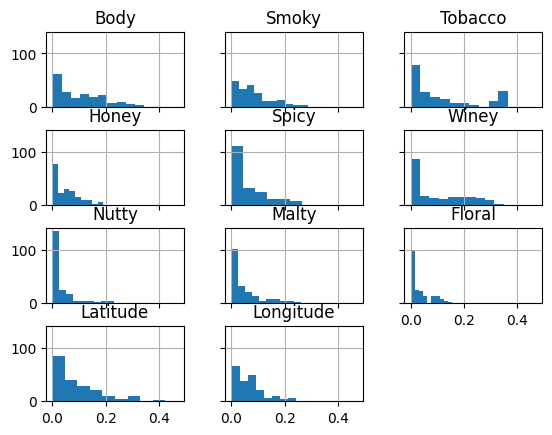

In [44]:
# Verteilung der Mutual Information je Merkmal
result.drop(["ncluster", "group"], axis = 1).hist(sharex = True, sharey = True);

Bei den meisten Merkmalen liegt die Mutual Information für die meisten Cluster nahe 0: Ein Merkmal ist also meist nur für einzelne Cluster wichtig. `Tobacco` fällt durch eine zweigipflige Verteilung auf. Entweder spielt das Merkmal für ein Cluster kaum eine Rolle, oder es ist mit Werten um 0,35 sehr wichtig. Das passt dazu, dass nur wenige Whiskys eine Tabaknote haben und diese häufig ein eigenes Cluster bilden.

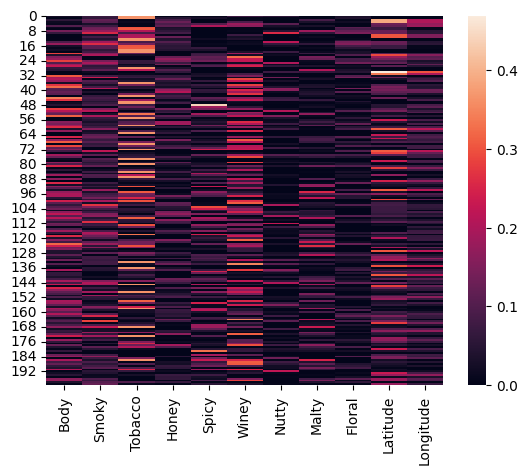

In [45]:
# Heatmap: eine Zeile je Cluster, eine Spalte je Merkmal
sns.heatmap(result.drop(["ncluster","group"], axis = 1));

Jede Zeile der Heatmap ist ein Cluster aus einem der 50 Modelle, jede Spalte ein Merkmal. Helle Felder bedeuten eine hohe Mutual Information. Die hellen Streifen bei `Tobacco` und `Latitude` zeigen, dass diese Merkmale in vielen Modellen die Zugehörigkeit zu einem Cluster stark bestimmen, während `Nutty` und `Floral` fast durchgehend dunkel bleiben. Solche Merkmale könnte man für die Clusteranalyse weglassen, ohne viel Information zu verlieren.

## Zusammenfassung

* **k-means** teilt die Daten in eine vorgegebene Anzahl von Clustern ein. Die Elbow-Methode und die Silhouette-Analyse helfen bei der Wahl dieser Anzahl.
* **Hierarchisches Clustering** (hier Birch) fasst Beobachtungen schrittweise zusammen und hängt nicht von zufälligen Startwerten ab.
* **DBSCAN** findet dichte Regionen, bestimmt die Anzahl der Cluster selbst und markiert Ausreißer als Rauschen.
* **DENCLUE** schätzt eine glatte Dichtefunktion und ordnet jede Beobachtung dem Dichte-Gipfel (Attraktor) zu, zu dem sie bergauf gelangt.
* **PageRank** misst, wie zentral ein Knoten in einem Netzwerk ist. Im Whisky-Netzwerk sind das die Whiskys mit typischem, ausgewogenem Profil.
* Das **Stochastic Block Model** beschreibt Netzwerke, in denen die Kantenwahrscheinlichkeit nur von den Blöcken der Knoten abhängt. Mit Spectral Clustering lassen sich die Blöcke schätzen.
* Im Whisky-Datensatz zeigt sich ein klares rauchig-torfiges Cluster (vor allem Islay). Geschmack und Herkunftsregion hängen zusammen, wie die Analyse der Merkmale zeigt.

## Quellen

* https://www.kaggle.com/datasets/koki25ando/scotch-whisky-dataset
* https://simplemaps.com/gis/country/gb
* https://geopandas.org/
* https://scikit-learn.org/stable/modules/clustering.html
* https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html
* https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html
* https://www.w3schools.com/python/python_ml_k-means.asp
* https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.link_analysis.pagerank_alg.pagerank.html
* https://networkx.org/documentation/stable/reference/generated/networkx.generators.community.stochastic_block_model.html
* https://scikit-learn.org/stable/modules/clustering.html#spectral-clustering
* Hinneburg, A. und Keim, D. A. (1998): An Efficient Approach to Clustering in Large Multimedia Databases with Noise. KDD-98.